# Predictive Analytics Mini Project
## Student Pass/Fail Prediction using Logistic Regression

**Course alignment:** CSE3141 Predictive Analytics  
**ML model:** Logistic Regression 
**Task:** Binary classification (0 = Fail, 1 = Pass)  

### Project workflow
1. Load and inspect raw data
2. Identify missing values and duplicate records
3. Validate data and fix invalid attendance percentages
4. Remove duplicates
5. Detect and cap outliers using IQR
6. Handle missing values using median imputation
7. Perform EDA and visualizations
8. Split data into training and test sets
9. Standardize features and train Logistic Regression
10. Evaluate the model and make an example prediction




In [2]:
# Cell 1: Import libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)


In [3]:
# Cell 2: Load the dataset
DATA_PATH = Path("data/student_performance_raw.csv")
df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())


Dataset shape: (31, 4)


,study_hours,attendance_percent,previous_score,passed
0,0.5,42.0,28.0,0
1,1.0,50.0,35.0,0
2,1.2,48.0,32.0,0
3,1.5,55.0,40.0,0
4,1.8,NaN,38.0,0


## 1. Initial data inspection

In [4]:
# Inspect column types, missing values, duplicates and summary statistics
print("Data types:")
display(df_raw.dtypes.rename("dtype").to_frame())

print("\nMissing values per column:")
display(df_raw.isna().sum().rename("missing_count").to_frame())

print("\nExact duplicate rows:", df_raw.duplicated().sum())

print("\nDescriptive statistics:")
display(df_raw.describe().T)


Data types:


,dtype
study_hours,float64
attendance_percent,float64
previous_score,float64
passed,int64



Missing values per column:


,missing_count
study_hours,1
attendance_percent,1
previous_score,1
passed,0



Exact duplicate rows: 1

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
study_hours,30.0,5.266667,6.031774,0.5,2.55,4.35,6.15,35.0
attendance_percent,30.0,76.433333,24.340520,42.0,63.50,74.00,85.50,180.0
previous_score,30.0,56.900000,16.381971,28.0,45.25,55.00,69.25,90.0
passed,31.0,0.483871,0.508001,0.0,0.00,0.00,1.00,1.0


## 2. Data validation

Attendance is a percentage, so valid values must be between 0 and 100. Values outside this range are treated as invalid and converted to missing values, which will be imputed later.

In [5]:
df = df_raw.copy()

invalid_attendance_mask = (
    (df["attendance_percent"] < 0) |
    (df["attendance_percent"] > 100)
)
print("Invalid attendance values:", int(invalid_attendance_mask.sum()))

df.loc[invalid_attendance_mask, "attendance_percent"] = np.nan
display(df.loc[invalid_attendance_mask])


Invalid attendance values: 1


,study_hours,attendance_percent,previous_score,passed
25,7.0,NaN,73.0,1


## 3. Remove duplicate records

In [6]:
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", duplicates_before)
print("Shape after duplicate removal:", df.shape)


Duplicate rows removed: 1
Shape after duplicate removal: (30, 4)


## 4. Detect and treat outliers using the IQR method

For each numeric input feature:

- \(IQR = Q3 - Q1\)
- Lower bound = \(Q1 - 1.5 × IQR\)
- Upper bound = \(Q3 + 1.5 × IQR\)

Values outside the bounds are flagged as potential outliers. Here, they are capped at the corresponding bound so that rows are retained. Outliers are not automatically errors, so this treatment should be justified in a real project.

In [7]:
FEATURES = ["study_hours", "attendance_percent", "previous_score"]
TARGET = "passed"

outlier_summary = []

for col in FEATURES:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = df[col].notna() & ((df[col] < lower) | (df[col] > upper))
    outlier_summary.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outliers_detected": int(mask.sum())
    })

    # Cap values to IQR bounds
    df[col] = df[col].clip(lower=lower, upper=upper)

display(pd.DataFrame(outlier_summary).round(2))


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outliers_detected
0,study_hours,2.50,6.2,3.70,-3.05,11.75,1
1,attendance_percent,62.75,84.5,21.75,30.12,117.12,0
2,previous_score,45.00,70.0,25.00,7.50,107.50,0


## 5. Check missing values after cleaning

In [8]:
print("Missing values remaining before imputation:")
display(df.isna().sum().rename("missing_count").to_frame())

print("Cleaned dataset preview:")
display(df.head(10))


Missing values remaining before imputation:


,missing_count
study_hours,1
attendance_percent,2
previous_score,1
passed,0


Cleaned dataset preview:


,study_hours,attendance_percent,previous_score,passed
0,0.5,42.0,28.0,0
1,1.0,50.0,35.0,0
2,1.2,48.0,32.0,0
3,1.5,55.0,40.0,0
4,1.8,NaN,38.0,0
5,2.0,60.0,43.0,0
6,2.2,58.0,41.0,0
7,2.5,62.0,45.0,0
8,2.7,65.0,48.0,0
9,3.0,63.0,46.0,0


## 6. Exploratory Data Analysis (EDA)

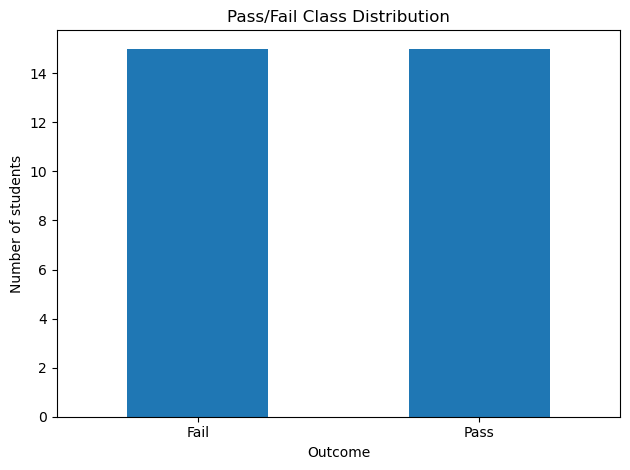

In [9]:
# Class distribution
df[TARGET].value_counts().sort_index().rename(index={0: "Fail", 1: "Pass"}).plot(
    kind="bar", xlabel="Outcome", ylabel="Number of students",
    title="Pass/Fail Class Distribution"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


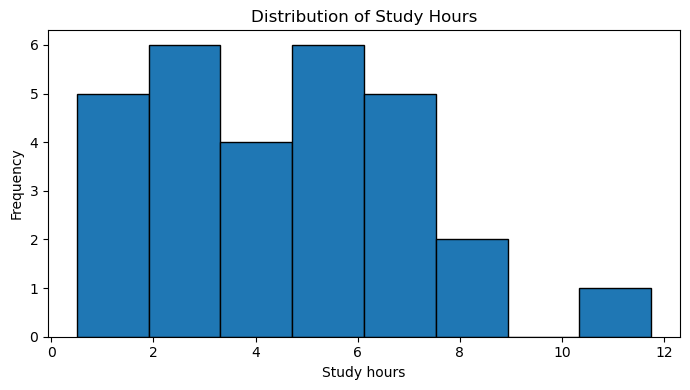

In [10]:
# Distribution of study hours
plt.figure(figsize=(7, 4))
plt.hist(df["study_hours"].dropna(), bins=8, edgecolor="black")
plt.xlabel("Study hours")
plt.ylabel("Frequency")
plt.title("Distribution of Study Hours")
plt.tight_layout()
plt.show()


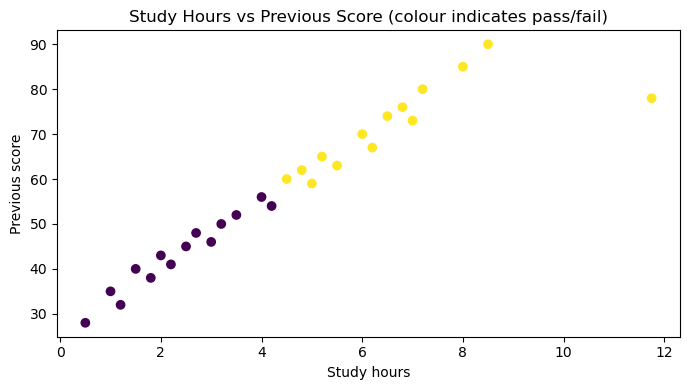

In [11]:
# Relationship between study hours and previous score
plt.figure(figsize=(7, 4))
plt.scatter(df["study_hours"], df["previous_score"], c=df[TARGET])
plt.xlabel("Study hours")
plt.ylabel("Previous score")
plt.title("Study Hours vs Previous Score (colour indicates pass/fail)")
plt.tight_layout()
plt.show()


In [12]:
# Correlation matrix for numeric columns
display(df.corr(numeric_only=True).round(2))


,study_hours,attendance_percent,previous_score,passed
study_hours,1.00,0.93,0.94,0.82
attendance_percent,0.93,1.00,0.99,0.84
previous_score,0.94,0.99,1.00,0.85
passed,0.82,0.84,0.85,1.00


## 7. Train-test split

We split the data before fitting the imputer and scaler. This prevents preprocessing statistics from the test set leaking into model training. A stratified split helps preserve the pass/fail ratio.

In [13]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())


Training feature shape: (22, 3)
Testing feature shape: (8, 3)

Training class proportions:


,proportion
passed,
1,0.5
0,0.5



Testing class proportions:


,proportion
passed,
0,0.5
1,0.5


## 8. Missing-value imputation, feature scaling and model training

- **Missing values:** median imputation for numeric features.
- **Scaling:** `StandardScaler` standardizes features.
- **Model:** Logistic Regression only.

The imputer and scaler are inside a pipeline, so they are fitted using training data only.

In [15]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(random_state=42, max_iter=1000))
])

model.fit(X_train, y_train)
print("Logistic Regression model trained.")


Logistic Regression model trained.


## 9. Create a model-ready dataset

In [16]:
# This export is for inspection only. Imputation values are learned from training data.
X_imputed = pd.DataFrame(
    model.named_steps["imputer"].transform(X),
    columns=FEATURES,
    index=X.index
)
model_ready_df = X_imputed.copy()
model_ready_df[TARGET] = y

display(model_ready_df.head(10))

# Save CSV outputs beside the notebook in an outputs folder.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
df.to_csv(OUTPUT_DIR / "cleaned_before_imputation.csv", index=False)
model_ready_df.to_csv(OUTPUT_DIR / "model_ready_dataset.csv", index=False)
print("Saved cleaned and model-ready CSV files in:", OUTPUT_DIR.resolve())


,study_hours,attendance_percent,previous_score,passed
0,0.5,42.0,28.0,0
1,1.0,50.0,35.0,0
2,1.2,48.0,32.0,0
3,1.5,55.0,40.0,0
4,1.8,74.5,38.0,0
5,2.0,60.0,43.0,0
6,2.2,58.0,41.0,0
7,2.5,62.0,45.0,0
8,2.7,65.0,48.0,0
9,3.0,63.0,46.0,0


Saved cleaned and model-ready CSV files in: /Users/dhruvi/Desktop/predictive_analytics_mini_project 3/outputs


## 10. Model evaluation

In [17]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob) if y_test.nunique() == 2 else float("nan")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Accuracy: {accuracy:.3f}")
print(f"F1-score (Pass class): {f1:.3f}")
print(f"ROC-AUC: {auc:.3f}")

print("\nConfusion matrix (rows = actual, columns = predicted; [Fail, Pass]):")
display(pd.DataFrame(cm, index=["Actual Fail", "Actual Pass"],
                     columns=["Predicted Fail", "Predicted Pass"]))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=["Fail", "Pass"], zero_division=0
))


Accuracy: 1.000
F1-score (Pass class): 1.000
ROC-AUC: 1.000

Confusion matrix (rows = actual, columns = predicted; [Fail, Pass]):


,Predicted Fail,Predicted Pass
Actual Fail,4,0
Actual Pass,0,4



Classification report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



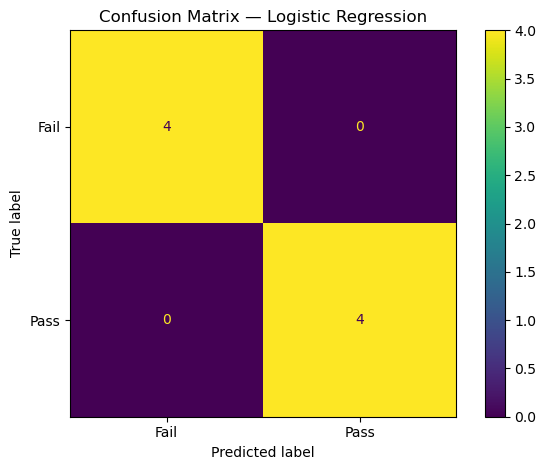

In [18]:
# Confusion matrix visualization
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail", "Pass"]).plot()
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()


## 11. Predict for a new student

In [20]:
new_student = pd.DataFrame([{
    "study_hours": 5.0,
    "attendance_percent": 80.0,
    "previous_score": 65.0
}])

predicted_class = int(model.predict(new_student)[0])
pass_probability = float(model.predict_proba(new_student)[0, 1])

print("Input:")
display(new_student)
print("Predicted outcome:", "Pass" if predicted_class == 1 else "Fail")
print(f"Estimated probability of passing: {pass_probability:.1%}")


Input:


,study_hours,attendance_percent,previous_score
0,5.0,80.0,65.0


Predicted outcome: Pass
Estimated probability of passing: 76.4%
